# Principles of Likelihood-based Inference

[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/gem-epidemics/colab/blob/master/eitv/likelihood_theory.ipynb)

This 90-minute workshop introduces the principles of likelihood-based inference: how a statistical model is used to learn about its parameters from data, and how certain we can be about the answers.

| Part | Topic | Time |
|---|---|---|
| 1 | Getting started, and models as data-generating processes | ~10 min |
| 2 | The likelihood function | ~15 min |
| 3 | Continuous data and the log-likelihood (Exercise 3.1) | ~15 min |
| 4 | Maximising the log-likelihood | ~10 min |
| 5 | How uncertain is our estimate? (Exercises 3.2 and 3.3) | ~20 min |
| 6 | An epidemic model (Exercise 3.4) | ~15 min |
| | Concluding remarks | ~5 min |
| | Extension: the Multinomial distribution (Exercise 3.5) | if time allows |

## LEARNING OUTCOMES
- Describe a statistical model as a _recipe for simulating data_, and inference as running the recipe backwards
- Explain how the likelihood function differs from a probability
- Use the likelihood function to estimate parameters, and to say how uncertain those estimates are
- Find maximum likelihood estimates (MLEs) numerically
- Write down the likelihood for a simple epidemic model

Throughout, you'll see boxes marked **For the mathematicians**.  These contain derivations and extra rigour for those who want it.  Everything else in the notebook makes sense without them, so feel free to skip them.

----

## Getting started

Run the cell below before anything else.  It loads the Python packages we need and defines some helper functions for drawing plots.  **You don't need to read or understand it** -- it's there so that the rest of the notebook can focus on the statistics rather than on plotting code.

In [1]:
# ---------------------------------------------------------------------------
# Setup and helper functions.  Just run this cell -- no need to read it!
# ---------------------------------------------------------------------------
import matplotlib.pyplot as plt
import numpy as np
import scipy as sp
import scipy.stats
import scipy.optimize
import scipy.integrate

%matplotlib inline

LR_CUTOFF = sp.stats.chi2.ppf(0.95, df=1) / 2     # 1.92: for 95% likelihood-ratio intervals
LR_CUTOFF_2D = sp.stats.chi2.ppf(0.95, df=2) / 2  # 3.00: for 95% regions for two parameters


def evaluate(f, values):
    """Apply the function f to every element of values (like sapply() in R)."""
    return np.array([f(v) for v in values])


def plot_two_readings(n, k_obs, p_fixed):
    """Plot the Binomial f(k | n, p) as a surface, as a probability, and as a likelihood."""
    p_grid = np.linspace(0.001, 0.999, 400)
    k_grid = np.arange(n + 1)
    surface = sp.stats.binom.pmf(k_grid[:, None], n, p_grid[None, :])
    prob = sp.stats.binom.pmf(k_grid, n, p_fixed)
    lik = sp.stats.binom.pmf(k_obs, n, p_grid)

    fig, ax = plt.subplots(1, 3, figsize=(15, 4.5))
    ax[0].pcolormesh(p_grid, k_grid, surface, shading="auto", vmax=0.15)
    ax[0].axvline(p_fixed, color="white", lw=2)
    ax[0].axhline(k_obs, color="C1", lw=2)
    ax[0].set(xlabel="Prevalence, $p$", ylabel="Number of positives, $k$", title=r"$f(k \mid n, p)$")
    ax[1].bar(k_grid, prob, color="grey")
    ax[1].set(xlabel="Number of positives, $k$", ylabel="Probability",
              title=f"Probability: fix $p={p_fixed}$, vary $k$")
    ax[2].plot(p_grid, lik, color="C1")
    ax[2].set(xlabel="Prevalence, $p$", ylabel="Likelihood",
              title=f"Likelihood: fix $k={k_obs}$, vary $p$")
    plt.tight_layout()
    plt.show()
    print(f"Probabilities over k add up to:  {prob.sum():.3f}")
    print(f"Area under the likelihood curve: {sp.integrate.trapezoid(lik, p_grid):.3f}")


def plot_loglik(loglik, lower, upper, xlabel="Parameter", relative=False,
                mle=None, true_value=None, interval=None, label=None):
    """Plot a one-parameter log-likelihood function between lower and upper."""
    grid = np.linspace(lower, upper, 300)
    values = evaluate(loglik, grid)
    if relative:
        values = values - values.max()
    plt.plot(grid, values, label=label)
    if mle is not None:
        plt.axvline(mle, color="C1", label="MLE")
    if true_value is not None:
        plt.axvline(true_value, color="grey", ls=":", label="true value")
    if interval is not None:
        plt.axvspan(interval[0], interval[1], color="C1", alpha=0.2, label="95% LR interval")
        if relative:
            plt.axhline(-LR_CUTOFF, color="C1", ls="--")
    if relative:
        plt.ylim(-8, 0.5)
        plt.ylabel("Log-likelihood minus its maximum")
    else:
        plt.ylabel("Log-likelihood")
    plt.xlabel(xlabel)
    if label is not None or mle is not None or true_value is not None or interval is not None:
        plt.legend()


def compare_sample_sizes(sample_sizes, true_rate, seed=3):
    """Simulate Exponential datasets of different sizes and overlay their relative log-likelihoods."""
    rng = np.random.default_rng(seed)
    for n_obs in sample_sizes:
        data = rng.exponential(scale=1 / true_rate, size=n_obs)
        def loglik(rate):
            return np.sum(sp.stats.expon.logpdf(data, scale=1 / rate))
        plot_loglik(loglik, 0.05, 0.5, relative=True, label=f"n = {n_obs}")
    plt.axvline(true_rate, color="grey", ls=":", label="true value")
    plt.xlabel(r"Recovery rate, $\gamma$")
    plt.legend()
    plt.title("Relative log-likelihood for different sample sizes")


def lr_interval(loglik, mle, lower, upper):
    """Approximate 95% likelihood-ratio interval: where the log-likelihood is within 1.92 of its maximum."""
    target = loglik(mle) - LR_CUTOFF
    def gap(x):
        return loglik(x) - target
    return sp.optimize.brentq(gap, lower, mle), sp.optimize.brentq(gap, mle, upper)


def hessian(f, x, h=1e-4):
    """Matrix of second derivatives of f at x, by finite differences.  Returns a number if x is a number."""
    is_number = np.ndim(x) == 0
    x = np.atleast_1d(np.asarray(x, dtype=float))
    g = (lambda v: f(v[0])) if is_number else f
    d = x.size
    H = np.zeros((d, d))
    for i in range(d):
        for j in range(d):
            ei = np.zeros(d); ei[i] = h
            ej = np.zeros(d); ej[j] = h
            H[i, j] = (g(x + ei + ej) - g(x + ei - ej) - g(x - ei + ej) + g(x - ei - ej)) / (4 * h * h)
    return H[0, 0] if is_number else H


def plot_contours(loglik, alpha_range, beta_range, mle=None, lr_region=False, wald_intervals=None,
                  xlabel=r"Shape, $\alpha$", ylabel=r"Rate, $\beta$"):
    """Contour plot of a two-parameter log-likelihood, relative to its maximum."""
    a = np.linspace(alpha_range[0], alpha_range[1], 200)
    b = np.linspace(beta_range[0], beta_range[1], 200)
    A, B = np.meshgrid(a, b)
    L = np.vectorize(loglik)(A, B)
    L = L - (loglik(*mle) if mle is not None else L.max())
    levels = [-20, -10, -6, -4, -3, -2, -1, -0.5]
    if lr_region:
        plt.contour(A, B, L, levels=levels, colors="grey", linewidths=0.8, linestyles="solid")
        plt.contour(A, B, L, levels=[-LR_CUTOFF_2D], colors="C1", linewidths=2, linestyles="solid")
        plt.plot([], [], color="C1", label="95% LR region")
    else:
        cs = plt.contour(A, B, L, levels=levels, linestyles="solid")
        plt.clabel(cs, fontsize=8)
    if mle is not None:
        plt.plot(mle[0], mle[1], "kx", label="MLE")
    if wald_intervals is not None:
        lo, hi = wald_intervals
        plt.plot([lo[0], hi[0], hi[0], lo[0], lo[0]], [lo[1], lo[1], hi[1], hi[1], lo[1]],
                 "C0--", label="Wald intervals")
    plt.xlabel(xlabel)
    plt.ylabel(ylabel)
    if mle is not None or lr_region or wald_intervals is not None:
        plt.legend(loc="upper left")
    plt.title("Log-likelihood relative to its maximum")

```{note}
**Python for R users.**  A few translations that will help as you read the code:

| Python | R |
|---|---|
| `sp.stats.binom.pmf(k, n, p)`, `sp.stats.binom.logpmf(k, n, p)` | `dbinom(k, n, p)`, `dbinom(k, n, p, log = TRUE)` |
| `rng.binomial(n, p)`, `rng.exponential(scale=5, size=100)` | `rbinom(1, n, p)`, `rexp(100, rate = 1/5)` |
| `np.sum(x)`, `np.log(x)`, `np.argmax(x)` | `sum(x)`, `log(x)`, `which.max(x)` |
| `sp.optimize.minimize_scalar(...)`, `sp.optimize.minimize(...)` | `optimize(...)`, `optim(...)` |
| `x ** 2` | `x^2` |
| `def f(x):` ... `return y` | `f <- function(x) { ... y }` |
| `x[0]` is the _first_ element | `x[1]` is the first element |

Indentation matters in Python: the lines that belong to a function or a loop are the indented ones.
```

```{note}
A few words we'll use a lot:

* **Parameter**: an unknown quantity in a model that we'd like to learn about, e.g. the prevalence of an infection, or a recovery rate.  Usually written with a Greek letter ($p$, $\gamma$, $\theta$, ...).
* **Estimate**: our best guess at a parameter from the data we have, usually written with a hat, e.g. $\hat{p}$.
* **Sampling distribution**: if we repeated the whole study many times, each time collecting new data, we'd get a slightly different estimate each time.  The spread of those estimates is the sampling distribution.
* **Confidence interval**: a range constructed so that, over many repeated studies, it would contain the true parameter value (say) 95% of the time.
```

## Models as data-generating processes

A **random variable** is a quantity whose value is determined by a random process: the number of positive tests in a survey, the time an individual remains infectious, the number of new cases in a week.  We describe a random variable with a **probability distribution**, which tells us which values are possible and how probable each one is.

The most useful way to think about a statistical model is as a **recipe for simulating data**.  A model strings together one or more random variables, each controlled by some parameters.  Give the recipe some parameter values, run it, and out comes a dataset that looks like the kind of data we might collect.

**Statistical inference runs the recipe backwards**: we have the data, and we want to learn about the parameter values that could have produced it.  The likelihood function is the tool that lets us do this.

```{admonition} For the mathematicians
:class: dropdown

Formally, we work on a probability space $(\Omega, \mathcal{F}, P)$, where $\Omega$ is the sample space of all possible outcomes, $\mathcal{F}$ is a $\sigma$-algebra of events (subsets of $\Omega$), and $P$ is a probability measure on $\mathcal{F}$.  A (real-valued) random variable is a measurable function $X: \Omega \to \mathbb{R}$.  For example, throwing two dice gives $\Omega = \{1,\dots,6\}^2$ with $\mathcal{F}$ its power set, and $X(\omega_1, \omega_2) = \omega_1 + \omega_2$ is the random variable "total score".

For this notebook we only need the distribution of $X$, i.e. its probability mass function (discrete $X$) or probability density function (continuous $X$).
```

````{codex-start}
:label: eitv-likelihood-example3.1
````

A Binomial random variable counts the number of "successes" in $n$ independent trials, each with probability $p$ of success.  For example, the number of people testing positive when we test $n$ people from a population with prevalence $p$:

$$
Z \sim \mbox{Binomial}(n, p)
$$

with _probability mass function_

$$
f(z \mid n, p) = { n \choose z}p^z(1-p)^{n-z}, \quad z = 0, 1, \dots, n.
$$

Because $Z$ is discrete, $f(z \mid n, p)$ really is a probability: the probability that we see exactly $z$ successes.

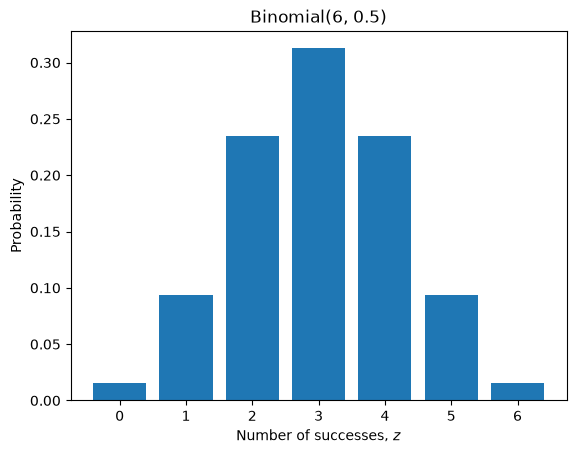

In [2]:
z = np.arange(7)                         # the numbers 0, 1, ..., 6 (like 0:6 in R)
prob = sp.stats.binom.pmf(z, 6, 0.5)     # like dbinom(z, 6, 0.5) in R

plt.bar(z, prob)
plt.xlabel("Number of successes, $z$")
plt.ylabel("Probability")
plt.title("Binomial(6, 0.5)");

````{codex-end}
````

````{codex-start}
:label: eitv-likelihood-example3.2
````

A Normally-distributed random variable $W$, characterised by its mean $\mu$ and variance $\sigma^2$:

$$
W \sim \mbox{Normal}(\mu, \sigma^2)
$$

with _probability density function_

$$
f(w \mid \mu, \sigma) = \frac{1}{\sqrt{2\pi}\,\sigma} e^{-\frac{1}{2\sigma^2}(w-\mu)^2}.
$$

$W$ is continuous, so $f(w \mid \mu, \sigma)$ is a probability _density_, not a probability: the probability of $W$ falling in a small interval around $w$ is roughly $f(w \mid \mu, \sigma)$ times the width of the interval.  A density can be greater than 1 -- try changing `scale=1` to `scale=0.2` below.

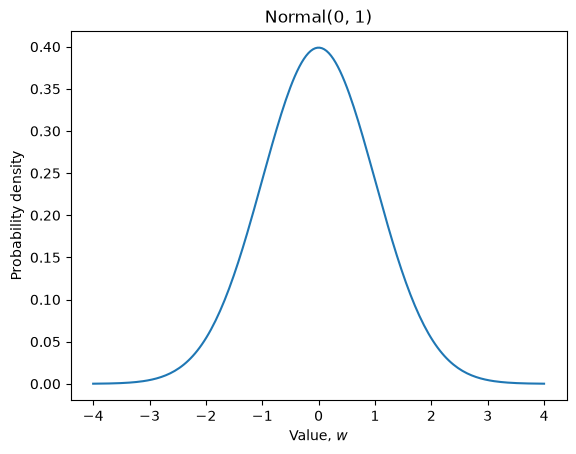

In [3]:
w = np.linspace(-4, 4, 200)                      # 200 evenly-spaced values, like seq(-4, 4, length.out = 200)
dens = sp.stats.norm.pdf(w, loc=0, scale=1)      # like dnorm(w, mean = 0, sd = 1)

plt.plot(w, dens)
plt.xlabel("Value, $w$")
plt.ylabel("Probability density")
plt.title("Normal(0, 1)");

````{codex-end}
````


----

## The likelihood function

### A prevalence survey

Suppose we test $n = 60$ randomly-chosen animals for an infection and find $k$ positives.  If the true prevalence is $p$, and animals are infected independently of one another, then a natural model is

$$
k \sim \mbox{Binomial}(n, p).
$$

Let's use this model as a recipe to simulate a survey, pretending the true prevalence is $p_0 = 0.15$.  In real life, of course, we don't know $p_0$ -- that's what we want to estimate.

````{codex-start}
:label: eitv-likelihood-example3.3
````

In [4]:
rng = np.random.default_rng(42)   # a random number generator, like set.seed(42) in R

n = 60
k_obs = rng.binomial(n, 0.15)     # like rbinom(1, n, 0.15)
print("Number of positives:", k_obs)

Number of positives: 11


````{codex-end}
````

### Same function, two readings

The Binomial formula $f(k \mid n, p) = {n \choose k}p^k(1-p)^{n-k}$ involves both the data $k$ and the parameter $p$.  We can read it in two different ways:

* **As a probability**: fix the parameter $p$, and ask how probable each possible dataset $k = 0, 1, \dots, n$ is.  This is the question we ask _before_ collecting data.
* **As a likelihood**: fix the data at what we actually observed, $k_{\text{obs}}$, and ask how well each possible value of $p$ explains it.  This is the question we ask _after_ collecting data.

The figure below shows $f(k \mid n, p)$ for every combination of $k$ and $p$.  The left panel is the whole surface.  A vertical slice through it (white line) gives a probability distribution over datasets.  A horizontal slice (orange line) at the data we observed gives the likelihood function.

Try changing `p_fixed` and re-running the cell.

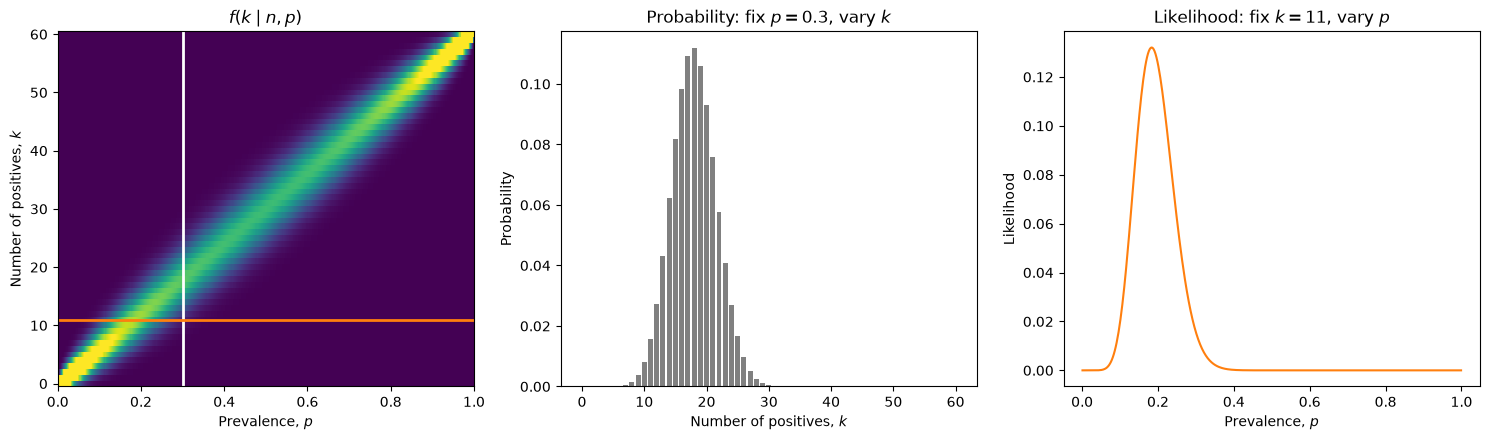

Probabilities over k add up to:  1.000
Area under the likelihood curve: 0.016


In [5]:
plot_two_readings(n=60, k_obs=k_obs, p_fixed=0.3)

Notice that the probabilities in the middle panel add up to 1, as probabilities must.  The area under the likelihood curve in the right panel does _not_ equal 1 (it happens to be $1/(n+1)$ here).  **The likelihood is not a probability distribution for the parameter.**  It does not tell us "the probability that $p = 0.2$".  It tells us how well $p = 0.2$ explains the data _compared with_ other values of $p$.

We write the likelihood function as

$$
L(p; k) \propto p^k (1-p)^{n-k}.
$$

The proportionality sign $\propto$ means we've dropped any factor that doesn't involve the parameter (here ${n \choose k}$).  That's allowed because only the _relative_ heights of the likelihood for different values of $p$ matter: multiplying the whole curve by a constant changes neither where its peak is nor its shape.

### The best-supported value

The value of $p$ at the peak of the likelihood is the one that best explains the data.  We call it the **maximum likelihood estimate** (MLE), $\hat{p}$.  The crudest way to find it is to evaluate the likelihood over a grid of values of $p$ and pick the largest.  We'll work with the _log_ of the likelihood, for reasons explained in the next section.

In [6]:
p_values = np.linspace(0.001, 0.999, 999)
log_lik = sp.stats.binom.logpmf(k_obs, n, p_values)   # like dbinom(k_obs, n, p_values, log = TRUE)

p_hat = p_values[np.argmax(log_lik)]                  # like p_values[which.max(log_lik)]
print("Grid-search MLE:", p_hat)
print("Proportion positive, k/n:", round(k_obs / n, 3))

Grid-search MLE: 0.183
Proportion positive, k/n: 0.183


Reassuringly, the MLE is (up to the grid resolution) just the proportion of positives in the sample, $\hat{p} = k/n$.  For simple models, maximum likelihood often reproduces the estimate common sense would suggest.  The power of the approach is that it keeps working when the model is too complicated for common sense to help.


----

## Continuous data: infectious periods

Now suppose we follow $n = 100$ infected individuals and record how many days each remains infectious, $y_1, \dots, y_n$.  If individuals recover at a constant rate $\gamma$ per day, the infectious period follows an Exponential distribution,

$$
y_i \sim \mbox{Exponential}(\gamma), \qquad f(y \mid \gamma) = \gamma e^{-\gamma y},
$$

with mean infectious period $1/\gamma$.  (If you've met the SIR model, this $\gamma$ is its recovery rate.  It has nothing to do with the Gamma distribution we'll meet later -- statisticians run out of Greek letters!)

````{codex-start}
:label: eitv-likelihood-example3.4
````

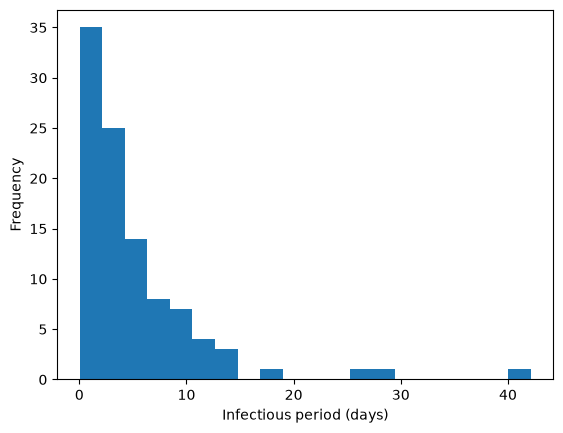

In [7]:
rng = np.random.default_rng(1)
y = rng.exponential(scale=5, size=100)   # true mean 5 days, i.e. rate 0.2.  Like rexp(100, rate = 0.2)

plt.hist(y, bins=20)
plt.xlabel("Infectious period (days)")
plt.ylabel("Frequency");

If individuals recover independently of one another, the joint density of all $n$ observations is the _product_ of the individual densities:

$$
f(y_1,\dots,y_n \mid \gamma) = \prod_{i=1}^{n} \gamma e^{-\gamma y_i}.
$$

Read as a function of $\gamma$, with the data fixed, this is the likelihood:

$$
L(\gamma; y_1,\dots,y_n) = \prod_{i=1}^{n}\gamma e^{-\gamma y_i}.
$$

````{codex-end}
````

### Working with the log-likelihood

In practice we almost always work with the natural logarithm of the likelihood, the **log-likelihood** $\ell = \log L$.  There are two reasons.

**Products become sums.**  Taking logs turns the product over observations into a sum, which is easier to write down, differentiate and compute with:

$$
\ell(\gamma; y_1,\dots,y_n) = \sum_{i=1}^{n} \log\left(\gamma e^{-\gamma y_i}\right) = n \log \gamma - \gamma \sum_{i=1}^{n} y_i.
$$

**Computers can't cope with the raw likelihood.**  Multiplying together many numbers that are typically small gives a result too small for the computer to represent, and it gets rounded to exactly zero (called _underflow_).  The sum of logs has no such problem.  Watch what happens with 1000 observations:

In [8]:
y_big = rng.exponential(scale=5, size=1000)
densities = sp.stats.expon.pdf(y_big, scale=5)

print("Likelihood (product of densities):    ", np.prod(densities))
print("Log-likelihood (sum of log densities):", np.sum(np.log(densities)))

Likelihood (product of densities):     0.0
Log-likelihood (sum of log densities): -2627.6487029609057


Taking logs doesn't move the peak: because $\log$ is an increasing function, whichever $\gamma$ maximises $L$ also maximises $\ell$.  As with the likelihood, we can add or drop any constant that doesn't involve $\gamma$, as this only shifts the curve up or down.

### Writing the log-likelihood as a function

In code, the log-likelihood is a function that takes a value of the parameter and returns a single number.  It adds up the log-density of each observation in `y`:

In [9]:
def exp_loglik(gamma):
    return np.sum(sp.stats.expon.logpdf(y, scale=1 / gamma))   # scipy uses scale = 1 / rate

print("Log-likelihood at gamma = 0.1:", exp_loglik(0.1))
print("Log-likelihood at gamma = 0.2:", exp_loglik(0.2))

Log-likelihood at gamma = 0.1: -282.1579475625299
Log-likelihood at gamma = 0.2: -264.74266776966067


The data support $\gamma = 0.2$ much better than $\gamma = 0.1$.  Plotting the function over a range of values gives the whole picture:

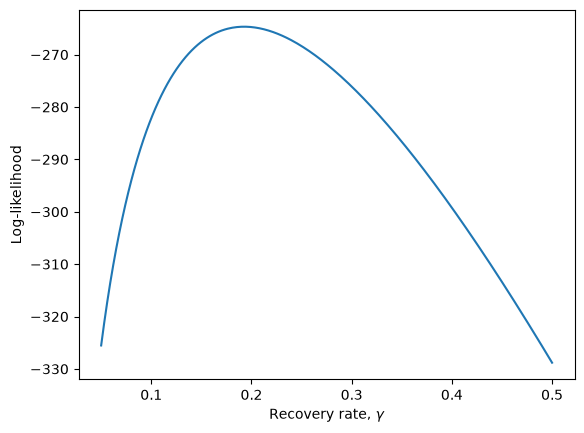

In [10]:
plot_loglik(exp_loglik, 0.05, 0.5, xlabel=r"Recovery rate, $\gamma$")

````{exercise-start}
:label: eitv-likelihood-ex3.1
````

The Exponential model assumes a constant recovery rate.  A more flexible model for delay times is the Gamma distribution.  Here are the delays, in weeks, from symptom onset to hospital admission for 10 patients:

In [11]:
z = np.array([0.28, 0.80, 0.50, 1.41, 2.51, 0.18, 0.73, 0.88, 0.61, 0.61])

Suppose these are _independent and identically-distributed_ observations $z_1,\dots,z_n \sim \mbox{Gamma}(\alpha, \beta)$, with shape $\alpha$ and rate $\beta$, which has density

$$
f(z \mid \alpha, \beta) = \frac{\beta^\alpha}{\Gamma(\alpha)} z^{\alpha - 1}e^{-\beta z}.
$$

Choose **one** of these routes (or both!):

1. **On paper:** write down an expression for the log-likelihood function for $\alpha$ and $\beta$ having observed the data $\mathbf{z}$.
2. **In code:** complete the function below so that it returns the log-likelihood, following the pattern of `exp_loglik` above.  Use `sp.stats.gamma.logpdf(z, a=alpha, scale=1 / beta)`.

```{tip}
Watch out for parameterisations!  The Gamma distribution is written in terms of either a rate $\beta$ or a scale $1/\beta$.  Scipy uses `a` for the shape $\alpha$, and `scale` $= 1/\beta$.
```

In [12]:
def loglik_gamma(alpha, beta):
    return ...  # replace ... with your code

````{exercise-end}
````

````{solution-start} eitv-likelihood-ex3.1
:class: dropdown
````

**On paper.**  First write down the likelihood as a product of densities:

$$
L(\alpha, \beta; z_1,\dots,z_n) = \prod_{i=1}^{n} \frac{\beta^\alpha}{\Gamma(\alpha)} z_i^{\alpha - 1}e^{-\beta z_i}
$$

and then take logs

$$
\ell(\alpha, \beta; z_1,\dots,z_n) = n \alpha \log \beta - n \log \Gamma(\alpha) + (\alpha - 1) \sum_{i=1}^{n} \log z_i - \beta \sum_{i=1}^{n} z_i.
$$

**In code.**

In [13]:
def loglik_gamma(alpha, beta):
    return np.sum(sp.stats.gamma.logpdf(z, a=alpha, scale=1 / beta))

loglik_gamma(2, 2)  # check it returns a single number

np.float64(-7.228375527025438)

````{solution-end}
````


----

## Maximising the log-likelihood

The maximum likelihood estimate is the value of the parameter at the peak of the (log-)likelihood:

$$
\hat{\gamma} = \underset{\gamma}{\mbox{argmax}}\,\ell(\gamma;y_1,\dots,y_n).
$$

There are three ways of finding it, in increasing order of sophistication:

1. **Grid search**: evaluate $\ell$ at lots of values and pick the largest, as we did for the prevalence.  Simple, but slow and imprecise, and hopeless with more than two or three parameters.
2. **Numerical optimisation**: let an algorithm "climb the hill" for us.  This is how MLEs are found in almost all real applications.
3. **Calculus**: for simple models, we can solve for the peak exactly (see the box below).

### Numerical optimisation

Optimisation algorithms start from an initial guess and repeatedly step "uphill" until they can't go any higher.  By convention, most optimisation routines _minimise_ a function (R's `optim()` does too), so we minimise the _negative_ log-likelihood, which is the same as maximising the log-likelihood.

For one parameter we can use `minimize_scalar`, giving it a range in which to search.  The range also keeps the recovery rate positive, as it must be.

In [14]:
def neg_loglik(gamma):
    return -exp_loglik(gamma)

fit = sp.optimize.minimize_scalar(neg_loglik, bounds=(0.001, 2), method="bounded")
gamma_hat = fit.x
print("MLE from optimiser:   ", round(gamma_hat, 4))
print("Analytic MLE, n / sum{y}:", round(len(y) / np.sum(y), 4))

MLE from optimiser:    0.1927
Analytic MLE, n / sum{y}: 0.1927


The optimiser agrees with the exact answer, $\hat{\gamma} = n / \sum_i y_i$ (derived in the box below), which is one over the mean infectious period.

```{admonition} For the mathematicians
:class: dropdown

**Finding the MLE analytically.**  At the maximum the gradient of $\ell$ (the _score_) is zero.  Here

$$
\frac{\mathrm{d}\ell}{\mathrm{d}\gamma} = \frac{n}{\gamma} - \sum_{i=1}^{n} y_i = 0 \quad\Longrightarrow\quad \hat{\gamma} = \frac{n}{\sum_{i=1}^{n} y_i},
$$

and $\mathrm{d}^2\ell/\mathrm{d}\gamma^2 = -n/\gamma^2 < 0$ confirms it's a maximum.

**Bias.**  An estimator is _unbiased_ if its expectation over repeated sampling equals the true value, $E[\hat{\gamma}] = \gamma_0$.  MLEs are not unbiased in general.  Here $\sum_i Y_i \sim \mbox{Gamma}(n, \gamma_0)$, so $E[1/\sum_i Y_i] = \gamma_0/(n-1)$ and

$$
E[\hat{\gamma}] = \frac{n}{n-1}\gamma_0,
$$

which overestimates $\gamma_0$, though the bias vanishes as $n \to \infty$.  Under regularity conditions MLEs are _consistent_ ($\hat{\gamma} \to \gamma_0$ in probability) and asymptotically efficient, which is the main theoretical justification for using them.
```


----

## How uncertain is our estimate?

An estimate on its own isn't much use: we also need to know how precise it is.  The likelihood tells us this through its **shape**.

### More data, sharper peak

The cell below simulates infectious-period datasets of three different sizes and plots each log-likelihood _relative to its maximum_, $\ell(\gamma) - \ell(\hat{\gamma})$, so that every curve peaks at zero.

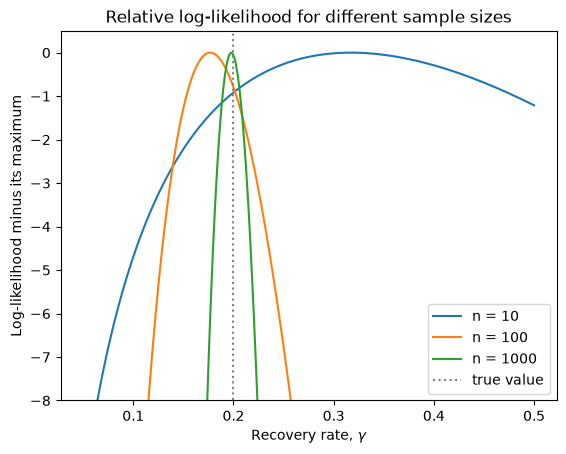

In [15]:
compare_sample_sizes([10, 100, 1000], true_rate=0.2)

With 10 observations the curve is broad: a wide range of values of $\gamma$ explain the data almost as well as the MLE.  With 1000 observations it is sharply peaked, and only values very close to the MLE are well supported.  **A sharper peak means a more precise estimate.**  There are two ways of turning this idea into a confidence interval.

### Likelihood-ratio confidence intervals

The most direct approach is to include every value of the parameter whose log-likelihood is "close enough" to the maximum.  It turns out that

$$
\left\{\gamma : \ell(\hat{\gamma}) - \ell(\gamma) \le 1.92\right\}
$$

is an approximate 95% confidence interval.  In words: draw a horizontal line 1.92 units below the peak, and read off where it crosses the curve.  The helper function `lr_interval` finds these crossing points for us, searching between a lower and upper limit we give it.

MLE 0.193, 95% LR interval (0.157, 0.233)


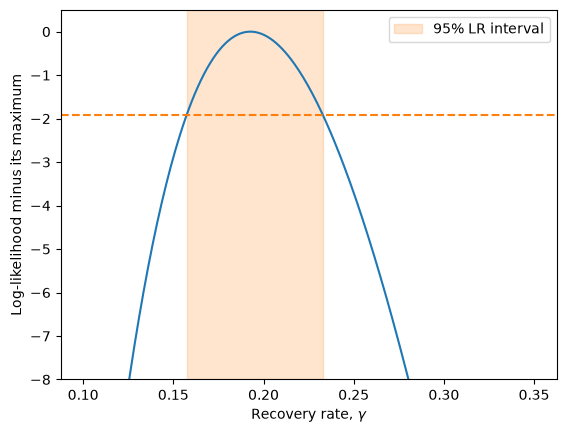

In [16]:
lr_lower, lr_upper = lr_interval(exp_loglik, gamma_hat, lower=0.001, upper=1)
print(f"MLE {gamma_hat:.3f}, 95% LR interval ({lr_lower:.3f}, {lr_upper:.3f})")

plot_loglik(exp_loglik, 0.1, 0.35, xlabel=r"Recovery rate, $\gamma$",
            relative=True, interval=(lr_lower, lr_upper))

```{admonition} For the mathematicians
:class: dropdown

The 1.92 comes from **Wilks' theorem**: under regularity conditions, if $\gamma_0$ is the true value then the likelihood-ratio statistic

$$
2\left[\ell(\hat{\gamma}) - \ell(\gamma_0)\right] \xrightarrow{d} \chi^2_d
$$

as $n \to \infty$, where $d$ is the number of parameters.  Inverting this test gives the interval above with cutoff $\chi^2_{1, 0.95}/2 = 3.84/2 = 1.92$.  For a joint region for two parameters the cutoff is $\chi^2_{2,0.95}/2 = 3.00$.

A nice property of likelihood-ratio intervals is that they are invariant to reparameterisation: the interval for $1/\gamma$ (the mean infectious period) is simply the reciprocal of the interval for $\gamma$.
```

### Curvature, standard errors and Wald intervals

The second approach measures how sharp the peak is by its **curvature**: the second derivative of the log-likelihood at the MLE.  A sharply-peaked curve bends quickly, so has a large (negative) second derivative.  The negative of this curvature is called the **observed information**,

$$
J(\hat{\gamma}) = -\left.\frac{\mathrm{d}^2\ell}{\mathrm{d}\gamma^2}\right|_{\gamma=\hat{\gamma}},
$$

and for large samples the variance of the MLE is approximately one over the information:

$$
\mathrm{Var}(\hat{\gamma}) \approx \frac{1}{J(\hat{\gamma})}, \qquad \mathrm{SE}(\hat{\gamma}) \approx \sqrt{\frac{1}{J(\hat{\gamma})}}.
$$

The helper function `hessian` calculates second derivatives numerically.  Because `neg_loglik` is the _negative_ log-likelihood, its second derivative is the observed information directly:

In [17]:
J = hessian(neg_loglik, gamma_hat)
se = np.sqrt(1 / J)

print("Standard error:", round(se, 4))
print("Analytic standard error, gamma_hat / sqrt(n):", round(gamma_hat / np.sqrt(len(y)), 4))

Standard error: 0.0193
Analytic standard error, gamma_hat / sqrt(n): 0.0193


If we believe the sampling distribution of $\hat{\gamma}$ is approximately Normal (which, for large samples, it is), we can form a **Wald** confidence interval in the familiar way, estimate $\pm$ 1.96 standard errors:

In [18]:
print(f"95% Wald interval: ({gamma_hat - 1.96 * se:.3f}, {gamma_hat + 1.96 * se:.3f})")
print(f"95% LR interval:   ({lr_lower:.3f}, {lr_upper:.3f})")

95% Wald interval: (0.155, 0.230)
95% LR interval:   (0.157, 0.233)


With 100 observations, the two intervals are very similar.  The Wald interval is always symmetric about the estimate; the likelihood-ratio interval follows the actual shape of the curve, which here is slightly skewed.

```{warning}
Wald intervals rely on the sampling distribution of $\hat{\gamma}$ being approximately Normal.  With small samples, or when the log-likelihood is far from symmetric about its peak, this can fail badly, and Wald intervals can even stray outside the allowed range of the parameter (e.g. below zero for a rate).  Likelihood-ratio intervals are usually more reliable in these situations.
```

With more than one parameter, the second derivatives form a matrix (the **Hessian**), and its inverse is the approximate covariance matrix of the estimates.  The standard errors are the square roots of its diagonal.  You'll do this in Exercise 3.3.

```{warning}
Some optimisers (including scipy's `minimize` with its default BFGS method) return an approximate inverse Hessian, `hess_inv`, as a by-product.  It's tempting to use it as the covariance matrix, but it's only a rough approximation the optimiser builds up to help it take good steps, and it can be badly wrong.  Calculate the Hessian at the MLE separately, as we do here.
```

```{admonition} For the mathematicians
:class: dropdown

The **(expected) Fisher information** is

$$
\mathcal{I}(\gamma) = -E_{\gamma}\left[\frac{\partial^2 \ell(\gamma; Y_1,\dots,Y_n)}{\partial \gamma^2}\right],
$$

the expectation taken over random samples $Y_1,\dots,Y_n$ from the model with parameter $\gamma$.  Under regularity conditions $\sqrt{n}(\hat{\gamma} - \gamma_0) \xrightarrow{d} N(0, i(\gamma_0)^{-1})$, where $i = \mathcal{I}/n$ is the information per observation.  In practice $\mathcal{I}(\gamma_0)$ is unknown, and we plug in either $\mathcal{I}(\hat{\gamma})$ or the observed information $J(\hat{\gamma})$; the latter is generally preferred (Efron & Hinkley, 1978) and is what numerical Hessians give us.

For the Exponential model $\partial^2\ell/\partial\gamma^2 = -n/\gamma^2$ doesn't depend on the data, so observed and expected information coincide: $J(\hat\gamma) = \mathcal{I}(\hat\gamma) = n/\hat{\gamma}^2$.
```

````{exercise-start}
:label: eitv-likelihood-ex3.2
````

Return to the Gamma model and the hospital-admission delays `z` from Exercise 3.1.  With two parameters, the log-likelihood is a surface, which we can draw as a contour map (like a map of hills).  Run:

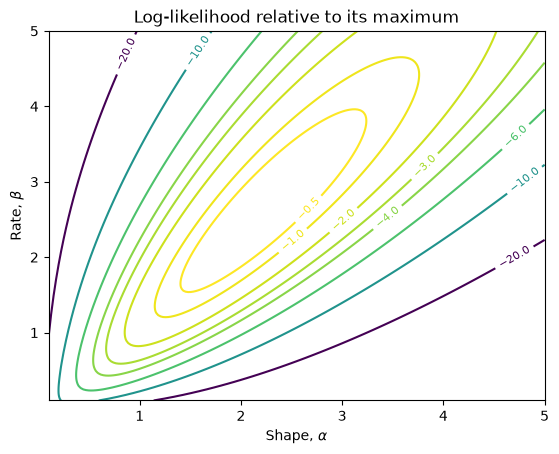

In [19]:
plot_contours(loglik_gamma, alpha_range=(0.1, 5), beta_range=(0.1, 5))

1. What do you notice about the shape of the contours?
2. What does this tell you about what the data can and can't tell us about $\alpha$ and $\beta$?

````{exercise-end}
````

````{solution-start} eitv-likelihood-ex3.2
:class: dropdown
````

The contours form long, narrow ridges running diagonally.  This tells us $\alpha$ and $\beta$ are strongly (positively) correlated: increasing $\alpha$ while also increasing $\beta$ explains the data almost as well.  This makes sense, because the mean of the Gamma distribution is $\alpha/\beta$, which the data pin down quite well, whereas the individual values of $\alpha$ and $\beta$ are much less well determined from only 10 observations.  The contours are also not symmetric ellipses, which is a warning that Normal (Wald) approximations may be poor.

````{solution-end}
````

````{exercise-start}
:label: eitv-likelihood-ex3.3
````

Now find the MLEs for the Gamma model and their uncertainty.

1. Complete `gamma_neg_loglik` below and run the cell to find the MLEs $\hat{\alpha}$ and $\hat{\beta}$.  With more than one parameter we use `sp.optimize.minimize` (like R's `optim`), which passes the parameters to our function together as a list, `par`.  The `bounds` keep both parameters positive.
2. Calculate the Hessian at the MLE with `hessian(gamma_neg_loglik, estimates)`, and invert it with `np.linalg.inv(...)` (like `solve()` in R) to get the approximate covariance matrix.  What do the off-diagonal elements represent, and are they consistent with your plot in Exercise 3.2?
3. Calculate approximate standard errors, `np.sqrt(np.diag(cov))`, and 95% Wald confidence intervals for $\hat{\alpha}$ and $\hat{\beta}$.
4. _(extension)_ Run `plot_contours(loglik_gamma, (0.1, 10), (0.1, 10), mle=estimates, lr_region=True, wald_intervals=(lower, upper))` to compare the 95% likelihood-ratio region with your Wald intervals.

```

In [ ]:
def gamma_neg_loglik(par):
    alpha, beta = par   # unpack the two parameters
    return ...          # replace ... with your code

fit = sp.optimize.minimize(gamma_neg_loglik, x0=[1, 1], bounds=[(0.01, None), (0.01, None)])
estimates = fit.x
print("alpha_hat, beta_hat:", np.round(estimates, 2))

````{exercise-end}
````

````{solution-start} eitv-likelihood-ex3.3
:class: dropdown
````

**1.**

In [21]:
def gamma_neg_loglik(par):
    alpha, beta = par
    return -loglik_gamma(alpha, beta)

fit = sp.optimize.minimize(gamma_neg_loglik, x0=[1, 1], bounds=[(0.01, None), (0.01, None)])
estimates = fit.x
print("alpha_hat, beta_hat:", np.round(estimates, 2))

alpha_hat, beta_hat: [2.19 2.57]


**2.**

In [22]:
H = hessian(gamma_neg_loglik, estimates)
cov = np.linalg.inv(H)
print(np.round(cov, 3))

[[0.834 0.98 ]
 [0.98  1.453]]


The off-diagonal elements are the covariance between $\hat{\alpha}$ and $\hat{\beta}$.  They are positive and large (a correlation of about 0.9), consistent with the diagonal ridge in the contour plot.

**3.**

In [23]:
se = np.sqrt(np.diag(cov))
lower = estimates - 1.96 * se
upper = estimates + 1.96 * se
print("Standard errors:", np.round(se, 2))
print("95% Wald interval for alpha:", np.round([lower[0], upper[0]], 2))
print("95% Wald interval for beta: ", np.round([lower[1], upper[1]], 2))

Standard errors: [0.91 1.21]
95% Wald interval for alpha: [0.4  3.98]
95% Wald interval for beta:  [0.21 4.93]


**4.**

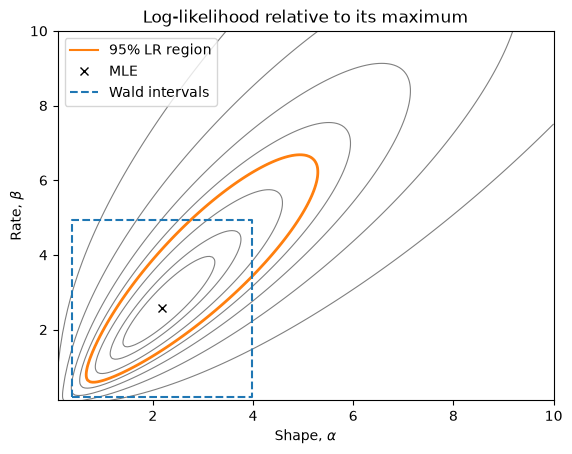

In [24]:
plot_contours(loglik_gamma, (0.1, 10), (0.1, 10), mle=estimates, lr_region=True, wald_intervals=(lower, upper))

The likelihood-ratio region is a skewed diagonal band: it extends much further towards large $\alpha$ and $\beta$ than towards small values.  The Wald intervals are symmetric by construction, so they miss this asymmetry entirely, and treating them separately (the box) ignores the strong correlation between the parameters.  With only 10 observations, the likelihood-ratio region is the more trustworthy summary.

````{solution-end}
````


----

## Building likelihoods from conditional probabilities: an epidemic model

So far our observations have been independent, so the likelihood was just a product of the individual probabilities.  In an epidemic, observations are _not_ independent: how many people become infected today depends on how many were infectious yesterday.  Can we still write down a likelihood?  Yes -- by following the recipe that generates the data, step by step.

### Transition rates

We describe an epidemic as a population moving between states.  For the SIR model these are **S**usceptible, **I**nfectious and **R**emoved, and individuals make the transitions $S \to I$ (infection) and $I \to R$ (removal).  Each transition from state $q$ to state $r$ happens at a **transition rate** $\lambda^{qr}(t, x_t)$, which may depend on time $t$ and on the current state of the population, $x_t = (S_t, I_t, R_t)$.  For the SIR model,

$$
\lambda^{SI}(t, x_t) = \frac{\beta I_t}{N}, \qquad \lambda^{IR}(t, x_t) = \gamma,
$$

where $\beta$ is the infection rate, $\gamma$ the removal rate, and $N$ the population size.  The infection rate depends on the state: the more infectious individuals there are, the faster susceptibles become infected.

### From rates to probabilities

We move the epidemic forward in time steps of length $\delta t$ (say, one day), and treat each rate as constant within a time step.  You've already met the key fact in the infectious-periods section: if an individual leaves its state at constant rate $\lambda$, its waiting time is Exponential($\lambda$), so the probability it makes the transition within a time step is

$$
\Pr(\text{transition within } \delta t) = 1 - e^{-\lambda \delta t}.
$$

Each of the $x^q_t$ individuals in state $q$ makes the transition independently with this probability, so the number of $q \to r$ transitions during the step, $y^{qr}_t$, is Binomial:

$$
y^{qr}_t \mid x_t \;\sim\; \mbox{Binomial}\left(x^q_t,\; 1 - e^{-\lambda^{qr}(t, x_t)\,\delta t}\right).
$$

We then update the state, $S_{t+1} = S_t - y^{SI}_t$, $I_{t+1} = I_t + y^{SI}_t - y^{IR}_t$ and $R_{t+1} = R_t + y^{IR}_t$, and repeat.  This is a **chain-binomial** model: a chain of Binomial draws, each depending on the state left by the one before.  It's the same structure used by the discrete-time state transition models in gemlib.

Here is the recipe in code.  The function `transition_rates` returns $\lambda^{SI}$ and $\lambda^{IR}$, and the `while` loop runs the epidemic until there are no infectives left.

````{codex-start}
:label: eitv-likelihood-example3.5
````

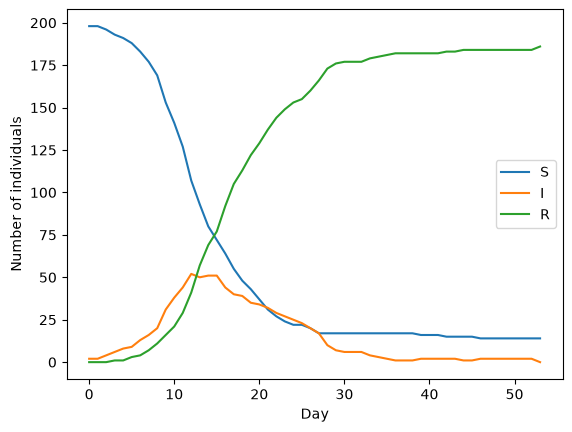

In [25]:
N = 200          # population size
delta_t = 1.0    # time step (days)

def transition_rates(t, S, I, R, beta, gamma):
    rate_SI = beta * I / N    # depends on the current state
    rate_IR = gamma           # constant here, but could depend on t or the state
    return rate_SI, rate_IR

# Simulate, pretending the true parameters are beta = 0.6 and gamma = 0.25
rng = np.random.default_rng(2)
S, I, R = [198], [2], [0]          # state at each time (Python lists, like vectors in R)
events_SI, events_IR = [], []      # number of each transition during each time step

while I[-1] > 0:                   # I[-1] is the last element of I
    t = len(events_SI)
    rate_SI, rate_IR = transition_rates(t, S[-1], I[-1], R[-1], beta=0.6, gamma=0.25)
    n_SI = rng.binomial(S[-1], 1 - np.exp(-rate_SI * delta_t))
    n_IR = rng.binomial(I[-1], 1 - np.exp(-rate_IR * delta_t))
    events_SI.append(n_SI)         # add to the end of the list
    events_IR.append(n_IR)
    S.append(S[-1] - n_SI)
    I.append(I[-1] + n_SI - n_IR)
    R.append(R[-1] + n_IR)

plt.plot(S, label="S")
plt.plot(I, label="I")
plt.plot(R, label="R")
plt.xlabel("Day")
plt.ylabel("Number of individuals")
plt.legend();

````{codex-end}
````

### The likelihood

To write down the likelihood we use the chain rule of probability, which says that any joint probability can be built up one step at a time:

$$
\Pr(y_0, y_1, \dots, y_{T-1} \mid x_0) = \Pr(y_0 \mid x_0)\,\Pr(y_1 \mid y_0, x_0) \cdots \Pr(y_{T-1} \mid y_{T-2}, \dots, y_0, x_0),
$$

where $y_t$ stands for all the transition counts in time step $t$.  Each term conditions on _everything_ that came before.  Our model makes this much simpler in two ways:

1. **Markov property.**  The transitions in step $t$ depend on the past only through the current state $x_t$.  Once we know who is currently susceptible, infectious and removed, the earlier history tells us nothing more.
2. **Independent transitions within a step.**  Given $x_t$, the $S \to I$ and $I \to R$ draws are independent of each other.

This is called **conditional independence**, and it means the likelihood is a product over time steps and transitions:

$$
L(\beta, \gamma) = \prod_{t=0}^{T-1}\; \prod_{(q,r)} {x^q_t \choose y^{qr}_t} \left(1 - e^{-\lambda^{qr}(t, x_t)\,\delta t}\right)^{y^{qr}_t} \left(e^{-\lambda^{qr}(t, x_t)\,\delta t}\right)^{x^q_t - y^{qr}_t},
$$

where $(q,r)$ runs over the transitions $S \to I$ and $I \to R$.  The log-likelihood is a sum of Binomial log-probabilities, one per transition per time step.

This only works because we observed every transition in _every_ time step, so every term can be evaluated.

```{admonition} For the mathematicians
:class: dropdown

Treating $\lambda^{qr}$ as constant over $[t, t+\delta t)$ makes the model a discrete-time approximation to the continuous-time Markov jump process with the same rates; as $\delta t \to 0$ it converges to that process.  Each individual can make at most one transition per time step, because the Binomial draws are made from the state at the start of the step.

If a state had more than one way out, say $q \to r$ and $q \to s$ with rates $\lambda^{qr}$ and $\lambda^{qs}$, the draws would no longer be independent Binomials but a single Multinomial over $\{r, s, \text{stay}\}$, with probabilities $\frac{\lambda^{qr}}{\lambda^{q\cdot}}(1 - e^{-\lambda^{q\cdot}\delta t})$, $\frac{\lambda^{qs}}{\lambda^{q\cdot}}(1 - e^{-\lambda^{q\cdot}\delta t})$ and $e^{-\lambda^{q\cdot}\delta t}$, where $\lambda^{q\cdot} = \lambda^{qr} + \lambda^{qs}$.  See the Multinomial extension below.
```

````{exercise-start}
:label: eitv-likelihood-ex3.4
````

Using the simulated epidemic above:

1. Complete the function below so that it returns the log-likelihood.  It loops over the time steps, adding one Binomial log-probability for each transition, exactly mirroring the product in the formula above.
2. Find the MLEs $\hat{\beta}$ and $\hat{\gamma}$ with `sp.optimize.minimize`, as in Exercise 3.3.  Do they agree with the values used to simulate the data?
3. Calculate standard errors from the Hessian, as in Exercise 3.3.
4. Plot the log-likelihood surface with `plot_contours(sir_loglik, (0.3, 1.0), (0.15, 0.35), mle=estimates, lr_region=True, xlabel=r"$\beta$", ylabel=r"$\gamma$")`.  How does its shape differ from the Gamma model's?  Can you explain why, by looking at which terms of the likelihood involve $\beta$ and which involve $\gamma$?
5. Discussion: in a real outbreak we'd rarely observe every transition exactly.  What if we only observed removals (e.g. cases detected when they're isolated)?  Or only some infections were detected?  Why does this make writing down the likelihood harder?

In [26]:
def sir_loglik(beta, gamma):
    total = 0
    for t in range(len(events_SI)):
        rate_SI, rate_IR = transition_rates(t, S[t], I[t], R[t], beta, gamma)
        prob_SI = ...   # replace ... with the probability that a susceptible is infected during the step
        prob_IR = ...   # replace ... with the probability that an infective is removed during the step
        total = total + ...   # replace ... with the two Binomial log-probabilities, using sp.stats.binom.logpmf
    return total

````{exercise-end}
````

````{solution-start} eitv-likelihood-ex3.4
:class: dropdown
````

**1.**

In [27]:
def sir_loglik(beta, gamma):
    total = 0
    for t in range(len(events_SI)):
        rate_SI, rate_IR = transition_rates(t, S[t], I[t], R[t], beta, gamma)
        prob_SI = 1 - np.exp(-rate_SI * delta_t)
        prob_IR = 1 - np.exp(-rate_IR * delta_t)
        total = total + sp.stats.binom.logpmf(events_SI[t], S[t], prob_SI)
        total = total + sp.stats.binom.logpmf(events_IR[t], I[t], prob_IR)
    return total

**2.**

In [28]:
def sir_neg_loglik(par):
    beta, gamma = par
    return -sir_loglik(beta, gamma)

fit = sp.optimize.minimize(sir_neg_loglik, x0=[0.5, 0.5], bounds=[(0.01, None), (0.01, None)])
estimates = fit.x
print("beta_hat, gamma_hat:", np.round(estimates, 3))

beta_hat, gamma_hat: [0.613 0.252]


The estimates are close to the values used to simulate the data, $\beta = 0.6$ and $\gamma = 0.25$.

**3.**

In [29]:
cov = np.linalg.inv(hessian(sir_neg_loglik, estimates))
print("Standard errors:", np.round(np.sqrt(np.diag(cov)), 3))
print("Covariance matrix:\n", np.round(cov, 5))

Standard errors: [0.045 0.019]
Covariance matrix:
 [[0.00205 0.     ]
 [0.      0.00034]]


**4.**

In [ ]:
plot_contours(sir_loglik, (0.3, 1.0), (0.15, 0.35), mle=estimates, lr_region=True,
              xlabel=r"Infection rate, $\beta$", ylabel=r"Removal rate, $\gamma$")

Unlike the Gamma model's diagonal ridge, the contours here are lined up with the axes, and the off-diagonal elements of the covariance matrix are essentially zero.  That's because the likelihood _factorises_: the $S \to I$ terms involve only $\beta$, and the $I \to R$ terms involve only $\gamma$.  So $\ell(\beta, \gamma) = \ell_1(\beta) + \ell_2(\gamma)$, and the two parameters can be estimated separately.  This is a consequence of observing every transition.

**5.**  If some transitions aren't observed, then the states $x_t$ that appear in each term of the product are no longer known.  The likelihood becomes a _sum_ over every epidemic history consistent with what we did observe, which quickly becomes far too large to compute directly.  Unobserved quantities like these are called **latent variables**, and handling them is where methods such as data-augmentation MCMC come in.  Notice too that $\beta$ and $\gamma$ would then no longer separate neatly: with only removals observed, many combinations of infection and removal rates can produce similar-looking data.

````{solution-end}
````

### Extension: the Multinomial distribution

The same chain-rule idea applies to any sequential recipe, and the Multinomial distribution is also what you need when a state has more than one way out.  A Multinomial distribution sorts $n$ objects into $d$ categories according to a vector of probabilities $\mathbf{p} = (p_1, \dots, p_d)$:

$$
\mathbf{y} \sim \mbox{Multinomial}(n, \mathbf{p}).
$$

One way to draw from it is through a sequence of Binomial draws: decide how many objects go in category 1, then how many of the _remaining_ objects go in category 2, and so on.  Whatever is left over goes in the last category.

In [ ]:
probs = [0.2, 0.3, 0.4, 0.1]
n_left = 100     # objects not yet assigned
p_left = 1.0     # total probability of the categories not yet filled
counts = []

for p_j in probs[:-1]:                          # every category except the last
    y_j = rng.binomial(n_left, p_j / p_left)
    counts.append(y_j)
    n_left = n_left - y_j
    p_left = p_left - p_j

counts.append(n_left)
print(counts)

Here each draw depends on _all_ the draws before it, through the number of objects still left, $n - y_1 - \dots - y_{j-1}$.  (The final count $y_4$ isn't random at all once $y_1, y_2, y_3$ are known.)  By the chain rule,

$$
\Pr(y_1, y_2, y_3, y_4) = \Pr(y_1)\,\Pr(y_2 \mid y_1)\,\Pr(y_3 \mid y_1, y_2)\,\Pr(y_4 \mid y_1, y_2, y_3).
$$

```{exercise}
:label: eitv-likelihood-ex3.5

1. Write down each term of the factorisation above as a Binomial probability, with the appropriate number of trials and re-normalised success probability, and multiply them together.
2. Show that your expression is proportional to $p_1^{y_1}p_2^{y_2}p_3^{y_3}(1-p_1-p_2-p_3)^{n-y_1-y_2-y_3}$, the Multinomial likelihood.
```


----

## Concluding remarks

In this notebook, we have:

1. treated statistical models as recipes for simulating data, with inference running the recipe backwards;
2. seen that the likelihood is the probability (or density) of the observed data, read as a function of the parameters -- and that it is _not_ a probability distribution for the parameters;
3. found maximum likelihood estimates (MLEs) by grid search, numerical optimisation and calculus;
4. used the shape of the log-likelihood to quantify uncertainty, through likelihood-ratio intervals and through curvature-based standard errors and Wald intervals;
5. used conditional independence and the chain rule to write down the likelihood for an epidemic model, where observations are not independent.

Maximum likelihood goes _much_ further than this primer, to deal with highly correlated parameters, unobserved (latent) variables, and situations where the large-sample approximations used here break down.  Some good references:

* Pawitan, Y. (2001) _In All Likelihood: Statistical Modelling and Inference Using Likelihood_.  Oxford University Press.  A readable, applied-friendly treatment.
* Casella, G. and Berger, R. L. (2002) _Statistical Inference_, 2nd edition.  Duxbury.  The standard mathematical text.
* [Le Cam, L. (1990) "Maximum likelihood: an introduction".  _International Statistical Review_ __58__(2): 153–171.](https://www.jstor.org/stable/1403464)